### Import Library

In [7]:
import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

### Load Data Label Manual & Inset Lexicon

In [2]:
MANUAL_PATH = '../../data/labeled/manual_labeling.csv'
INSET_PATH = '../../data/labeled/inset_labeling.csv'

# LOAD FILE
df_manual = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")

# File InSet hasil labeling
df_inset = pd.read_csv(INSET_PATH, encoding="utf-8-sig")

print("Data manual:", df_manual.shape)
print("Data InSet :", df_inset.shape)

print("\nKolom manual:", df_manual.columns.tolist())
print("Kolom InSet :", df_inset.columns.tolist())

Data manual: (8790, 2)
Data InSet : (48546, 8)

Kolom manual: ['text', 'label']
Kolom InSet : ['text', 'original_text', 'clean_text', 'label_inset', 'score_inset', 'matched_terms', 'sarcasm_detected', 'contrast_detected']


### Merapihkan Nama Label

In [3]:
def normalize_label(label):
    label = str(label).strip().lower()

    mapping = {
        "negative": "negative",
        "negatif": "negative",
        "neg": "negative",

        "positive": "positive",
        "positif": "positive",
        "pos": "positive",

        "neutral": "neutral",
        "netral": "neutral",
        "neu": "neutral"
    }

    return mapping.get(label, label)


df_manual["label_manual"] = df_manual["label"].apply(normalize_label)
df_inset["label_inset"] = df_inset["label_inset"].apply(normalize_label)

print("Distribusi label manual:")
print(df_manual["label_manual"].value_counts())

print("\nDistribusi label InSet:")
print(df_inset["label_inset"].value_counts())

Distribusi label manual:
label_manual
negative    6043
positive    1691
neutral     1056
Name: count, dtype: int64

Distribusi label InSet:
label_inset
negative    26871
positive    11451
neutral     10224
Name: count, dtype: int64


### Menggabungkan data manual dengan hasil InSet

Karena file label manual berisi 8.790 data, sedangkan InSet berisi 48.546 data, maka bagian yang dibandingkan adalah 8.790 data pertama.

In [4]:
# Ambil jumlah data sesuai data manual
n_manual = len(df_manual)

# Ambil subset InSet sebanyak data manual
df_inset_subset = df_inset.iloc[:n_manual].copy().reset_index(drop=True)
df_manual_subset = df_manual.copy().reset_index(drop=True)

# Buat dataframe gabungan
df_svm_inset = pd.DataFrame({
    "manual_text": df_manual_subset["text"],
    "clean_text": df_inset_subset["clean_text"],
    "label_manual": df_manual_subset["label_manual"],
    "label_inset": df_inset_subset["label_inset"],
    "score_inset": df_inset_subset["score_inset"]
})

# Hapus data kosong
df_svm_inset["clean_text"] = df_svm_inset["clean_text"].fillna("").astype(str)
df_svm_inset = df_svm_inset[df_svm_inset["clean_text"].str.strip() != ""]

print("Jumlah data siap pakai:", len(df_svm_inset))
print(df_svm_inset.head())

Jumlah data siap pakai: 8784
                               manual_text  \
0                              adil jokowi   
1  moga pak prabowo tidak kayak begini pak   
2          siap siap mulyono semua panggil   
3         pilih foto biar kesan siapa tuan   
4                       lo bayar nih utang   

                                clean_text label_manual label_inset  \
0                              adil jokowi     negative    negative   
1  moga pak prabowo tidak kayak begini pak      neutral    negative   
2          siap siap mulyono semua panggil     negative    negative   
3         pilih foto biar kesan siapa tuan     negative    negative   
4                       lo bayar nih utang     negative    negative   

   score_inset  
0         -3.0  
1         -2.0  
2         -4.0  
3         -4.0  
4         -7.0  


### Menampilkan sampel data hasil penggabungan label manual dan label IndoBERT

In [5]:
df_svm_inset[[
    "manual_text",
    "clean_text",
    "label_manual",
    "label_inset",
    "score_inset"
]].head(10)

,manual_text,clean_text,label_manual,label_inset,score_inset
0,adil jokowi,adil jokowi,negative,negative,-3.0
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative,-2.0
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,negative,-4.0
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,negative,-4.0
4,lo bayar nih utang,lo bayar nih utang,negative,negative,-7.0
5,ijazah kamu mana wi,ijazah kamu mana wi,negative,neutral,0.0
6,jangan jadi indonesia pernah tipu satu keluarg...,jangan jadi indonesia pernah tipu satu keluarg...,negative,negative,-12.0
7,sir kok lebih tarik pinjam bunga lebih tinggi ...,sir kok lebih tarik pinjam bunga lebih tinggi ...,negative,positive,13.0
8,waris susah presiden sekarang pak,waris susah presiden sekarang pak,negative,positive,3.0
9,halo pak,halo pak,neutral,neutral,1.0


### Split Data 80% 20%

In [6]:
X = df_svm_inset["clean_text"]
y_inset = df_svm_inset["label_inset"]
y_manual = df_svm_inset["label_manual"]

# Split berdasarkan index agar y_train dan y_test bisa diambil dari label berbeda
indices = np.arange(len(df_svm_inset))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_manual
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Model dilatih dengan label InSet
y_train = y_inset.iloc[train_idx]

# Model diuji dengan label manual
y_test = y_manual.iloc[test_idx]

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\nDistribusi y_train label InSet:")
print(y_train.value_counts())

print("\nDistribusi y_test label manual:")
print(y_test.value_counts())

Jumlah data train: 7027
Jumlah data test : 1757

Distribusi y_train label InSet:
label_inset
negative    3896
positive    1731
neutral     1400
Name: count, dtype: int64

Distribusi y_test label manual:
label_manual
negative    1208
positive     338
neutral      211
Name: count, dtype: int64


### Training Model SVM dengan Label Inset Lexicon

In [9]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameter :", grid.best_params_)
print("Best Score :", grid.best_score_)

svm_inset_model = grid.best_estimator_

Best Parameter : {'svm__C': 1}
Best Score : 0.709539941375535


### Evaluasi terhadap label manual

In [10]:
y_pred = svm_inset_model.predict(X_test)

labels_order = ["negative", "neutral", "positive"]

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("HASIL EVALUASI SVM LABEL INSET TERHADAP LABEL MANUAL")
print("=" * 60)
print(f"Accuracy         : {accuracy:.4f}")
print(f"Macro Precision  : {precision_macro:.4f}")
print(f"Macro Recall     : {recall_macro:.4f}")
print(f"Macro F1-score   : {f1_macro:.4f}")
print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall   : {recall_weighted:.4f}")
print(f"Weighted F1-score : {f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels_order,
    zero_division=0
))

HASIL EVALUASI SVM LABEL INSET TERHADAP LABEL MANUAL
Accuracy         : 0.6261
Macro Precision  : 0.5207
Macro Recall     : 0.5691
Macro F1-score   : 0.5303
Weighted Precision: 0.6986
Weighted Recall   : 0.6261
Weighted F1-score : 0.6506

Classification Report:
              precision    recall  f1-score   support

    negative       0.84      0.66      0.74      1208
     neutral       0.25      0.44      0.32       211
    positive       0.47      0.61      0.53       338

    accuracy                           0.63      1757
   macro avg       0.52      0.57      0.53      1757
weighted avg       0.70      0.63      0.65      1757



In [11]:
import pandas as pd

hasil_inset = pd.DataFrame({
    'y_test': y_test.reset_index(drop=True),
    'y_pred_inset': y_pred
})

hasil_inset.to_csv('hasil_inset.csv', index=False)

print("Berhasil disimpan!")

Berhasil disimpan!


### Confusion Matrix

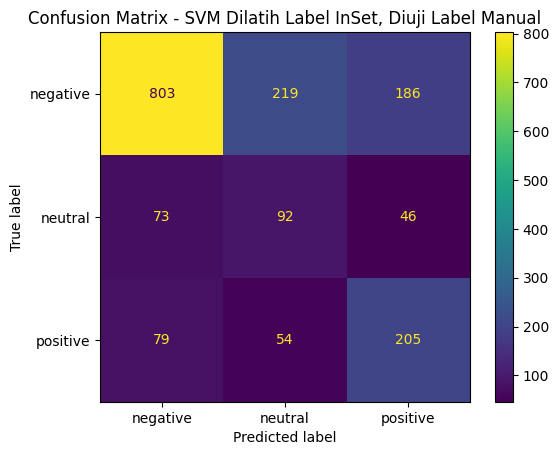

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels_order
)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_order
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - SVM Dilatih Label InSet, Diuji Label Manual")
plt.show()

### Analisis Eror

In [10]:
error_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'label_manual': y_test.reset_index(drop=True),
    'prediksi_svm': pd.Series(y_pred)
})

error_df = error_df[
    error_df['label_manual'] != error_df['prediksi_svm']
]

print(f"Jumlah salah klasifikasi: {len(error_df)}")

error_df.head(20)

Jumlah salah klasifikasi: 657


,text,label_manual,prediksi_svm
2,bukan jokowi,positive,negative
3,bismillah amin allahumma amin,positive,neutral
9,buat mantan presiden konslet bohong besar,negative,positive
15,maling,negative,neutral
17,video lucu,positive,neutral
18,jauh lebih banyak simpati bapak jokowi ketimba...,negative,neutral
20,terus doa paus apa pak lihat foto bpak doa,negative,positive
22,mau reuni kali hari kaya orang makan tidak yak...,neutral,positive
25,mau tanya pak ketua rawan solmet silfester mat...,negative,neutral
26,tamak,negative,neutral


### Mengidentifikasi Pola Kesalahan

In [11]:
error_df['jenis_error'] = (
    error_df['label_manual']
    + ' → ' +
    error_df['prediksi_svm']
)

error_summary = error_df['jenis_error'].value_counts()

print(error_summary)

jenis_error
negative → neutral     219
negative → positive    186
positive → negative     79
neutral → negative      73
positive → neutral      54
neutral → positive      46
Name: count, dtype: int64


### Evaluasi stabilitas model menggunakan 5-Fold Cross Validation


In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = cross_validate(
    svm_inset_model,
    X,
    y_inset,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("HASIL 5-FOLD CROSS VALIDATION")
print("=" * 70)

print(
    f"Accuracy      : "
    f"{cv_results['test_accuracy'].mean():.4f} ± "
    f"{cv_results['test_accuracy'].std():.4f}"
)

print(
    f"Macro F1      : "
    f"{cv_results['test_f1_macro'].mean():.4f} ± "
    f"{cv_results['test_f1_macro'].std():.4f}"
)

print(
    f"Weighted F1   : "
    f"{cv_results['test_f1_weighted'].mean():.4f} ± "
    f"{cv_results['test_f1_weighted'].std():.4f}"
)

HASIL 5-FOLD CROSS VALIDATION
Accuracy      : 0.7715 ± 0.0093
Macro F1      : 0.7189 ± 0.0112
Weighted F1   : 0.7694 ± 0.0096


In [13]:
cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Macro_F1": cv_results["test_f1_macro"],
    "Weighted_F1": cv_results["test_f1_weighted"]
})

cv_df

,Fold,Accuracy,Macro_F1,Weighted_F1
0,1,0.770063,0.716345,0.767200
1,2,0.772908,0.724587,0.771636
2,3,0.787137,0.735637,0.785082
3,4,0.769493,0.716513,0.767987
4,5,0.757973,0.701629,0.755037


### Simpan Hasil Prediksi

In [13]:
hasil_svm_inset = df_svm_inset.iloc[test_idx].copy()
hasil_svm_inset["pred_svm_inset"] = y_pred
hasil_svm_inset["benar_salah"] = hasil_svm_inset["label_manual"] == hasil_svm_inset["pred_svm_inset"]

hasil_svm_inset.to_csv(
    "hasil_svm_inset_vs_manual.csv",
    index=False,
    encoding="utf-8-sig"
)

print("File hasil prediksi disimpan sebagai: hasil_svm_inset_vs_manual.csv")

File hasil prediksi disimpan sebagai: hasil_svm_inset_vs_manual.csv
